$\textbf{SRM Uncertainty Propagation TEST}$

In [36]:
#DEFINITIONS
import skrf as rf
from skrf.calibration import TRL, TUGMultilineTRL
import numpy as np
import matplotlib.pyplot as plt
from u_srm_v2 import uSRM
from srm import SRM
import metas_unclib as munc
munc.use_linprop()

$\textbf{Add Test Data}$

In [37]:

short_tip = rf.Network('PCB/2Port_meas/Short_2Port_raw.s2p')
open_tip = rf.Network('PCB/2Port_meas/Open_2Port_raw.s2p')
load_tip = rf.Network('PCB/2Port_meas/Match_2Port_raw.s2p')
thru_tip = rf.Network('PCB/2Port_meas/Line_0_raw.s2p')
test_tip = rf.Network('PCB/2Port_meas/Impedance_raw.s2p')
line_0 = rf.Network('PCB/2Port_meas/Line_0_raw.s2p')
line_1 = rf.Network('PCB/2Port_meas/Line_1_raw.s2p')
line_2 = rf.Network('PCB/2Port_meas/Line_2_raw.s2p')
line_3 = rf.Network('PCB/2Port_meas/Line_3_raw.s2p')
line_4 = rf.Network('PCB/2Port_meas/Line_4_raw.s2p')
line_5 = rf.Network('PCB/2Port_meas/Line_5_raw.s2p')
line_6 = rf.Network('PCB/2Port_meas/Line_6_raw.s2p')
FWST = rf.Network('PCB/2Port_meas/FWST_Line_0.s1p')
RWST = rf.Network('PCB/2Port_meas/RWST_Line_0.s1p')
match_measured = rf.Network('PCB/2Port_meas/Match_2Port_raw.s2p')
match_def = rf.Network('match_0402.s1p')
freq = short_tip.frequency


$\textbf{Add Ideals}$

In [38]:
reciprocal_est = np.zeros((len(freq),2,2),dtype=complex)
reciprocal_est[0:len(freq),0,0] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),0,1] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,0] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,1] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est = rf.Network(frequency=freq,s=reciprocal_est,z0=50)

short_est = -1*np.ones(len(freq))
open_est = 1*np.ones(len(freq))
match_est = 0*np.ones((len(freq)))

match_est_2p = np.zeros((len(freq),2,2),dtype=complex)
match_est_2p[0:len(freq),0,0] = match_est
match_est_2p[0:len(freq),1,1] = match_est
match_est_2p = rf.Network(frequency=freq,s=match_est_2p,z0=50)

short_est_2p = np.zeros((len(freq),2,2),dtype=complex)
short_est_2p[0:len(freq),0,0] = short_est
short_est_2p[0:len(freq),1,1] = short_est
short_est_2p = rf.Network(frequency=freq,s=short_est_2p,z0=50)

open_est_2p = np.zeros((len(freq),2,2),dtype=complex)
open_est_2p[0:len(freq),0,0] = open_est
open_est_2p[0:len(freq),1,1] = open_est
open_est_2p = rf.Network(frequency=freq,s=open_est_2p,z0=50)

$\textbf{Perform SRM without Uncertainties}$

In [39]:
calSRM = uSRM(symmetric=[short_tip.s11,short_tip.s22, open_tip.s11, open_tip.s22, load_tip.s11, load_tip.s22],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=thru_tip,est_reciprocal=reciprocal_est,
            reciprocal_GammaA = [short_tip.s11, open_tip.s11, load_tip.s11],
            matchA=load_tip.s11, matchB=load_tip.s22,
            matchA_def=match_def.s11, matchB_def=match_def.s11,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex),
            0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex),
            0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex)],
            ureciprocal=0.001*np.ones((len(freq),8,8),dtype=complex),
            ureciprocal_GammaA=[0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex)],
            umatchA_def=0*np.ones((len(freq),2,2),dtype=complex),umatchB_def=0*np.ones((len(freq),2,2),dtype=complex),
            umatchA=0.001*np.ones((len(freq),2,2),dtype=complex),umatchB=0.001*np.ones((len(freq),2,2),dtype=complex),
            ureciprocal_GammaB=[0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex)])

calSRM1 = uSRM(symmetric=[short_tip.s11,short_tip.s22, open_tip.s11, open_tip.s22, load_tip.s11, load_tip.s22],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=thru_tip,est_reciprocal=reciprocal_est,
            reciprocal_GammaA = [short_tip.s11, open_tip.s11, load_tip.s11],
            matchA=load_tip.s11, matchB=load_tip.s22,
            matchA_def=match_def.s11, matchB_def=match_def.s11,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex),
            0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex),
            0.001*np.ones((len(freq),2,2),dtype=complex), 0.001*np.ones((len(freq),2,2),dtype=complex)],
            ureciprocal=0.001*np.ones((len(freq),8,8),dtype=complex),
            ureciprocal_GammaA=[0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex)],
            umatchA_def=0*np.ones((len(freq),2,2),dtype=complex),umatchB_def=0*np.ones((len(freq),2,2),dtype=complex),
            umatchA=0.001*np.ones((len(freq),2,2),dtype=complex),umatchB=0.001*np.ones((len(freq),2,2),dtype=complex),
            ureciprocal_GammaB=[0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex),0.001*np.ones((len(freq),2,2),dtype=complex)])




In [40]:
calSRM.u_run()
calSRM1.run()


uSRM is running...
Frequency: 0.02 GHz ... DONE!
Frequency: 0.04 GHz ... DONE!
Frequency: 0.06 GHz ... DONE!


C:\Program Files (x86)\METAS\Metas.UncLib\metas_unclib.py:198: ComplexWarning: Casting complex values to real discards the imaginary part
  c = [_Number(float(bi)) for bi in b.flatten('F')]


Frequency: 0.08 GHz ... DONE!
Frequency: 0.10 GHz ... DONE!
Frequency: 0.12 GHz ... DONE!
Frequency: 0.14 GHz ... DONE!
Frequency: 0.16 GHz ... DONE!
Frequency: 0.18 GHz ... DONE!
Frequency: 0.20 GHz ... DONE!
Frequency: 0.22 GHz ... DONE!
Frequency: 0.24 GHz ... DONE!
Frequency: 0.26 GHz ... DONE!
Frequency: 0.28 GHz ... DONE!
Frequency: 0.30 GHz ... DONE!
Frequency: 0.32 GHz ... DONE!
Frequency: 0.34 GHz ... DONE!
Frequency: 0.36 GHz ... DONE!
Frequency: 0.38 GHz ... DONE!
Frequency: 0.40 GHz ... DONE!
Frequency: 0.42 GHz ... DONE!
Frequency: 0.44 GHz ... DONE!
Frequency: 0.46 GHz ... DONE!
Frequency: 0.48 GHz ... DONE!
Frequency: 0.50 GHz ... DONE!
Frequency: 0.52 GHz ... DONE!
Frequency: 0.54 GHz ... DONE!
Frequency: 0.56 GHz ... DONE!
Frequency: 0.58 GHz ... DONE!
Frequency: 0.60 GHz ... DONE!
Frequency: 0.62 GHz ... DONE!
Frequency: 0.64 GHz ... DONE!
Frequency: 0.66 GHz ... DONE!
Frequency: 0.68 GHz ... DONE!
Frequency: 0.70 GHz ... DONE!
Frequency: 0.72 GHz ... DONE!
Frequency:

In [41]:
line_meas = [line_0, line_1, line_2, line_3, line_4, line_5, line_6]
line_lenghts = [0,0.5e-3,1.5e-3,4e-3,5.5e-3,6.5e-3,8.5e-3]


calmTRL = TUGMultilineTRL(line_meas=line_meas,line_lengths=line_lenghts,reflect_meas=short_tip,reflect_est=-1,er_est=3.0+0.01j,switch_term_fw=FWST.s11, switch_terms=[FWST,RWST])

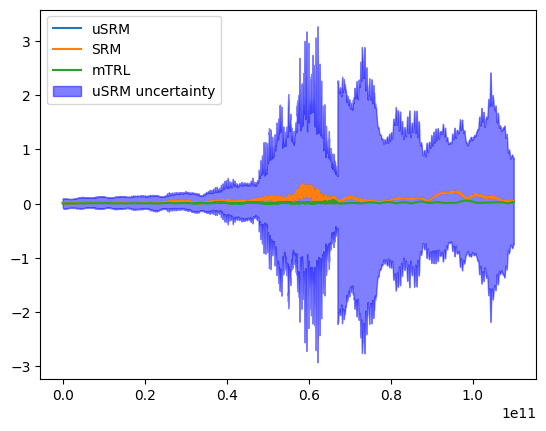

In [51]:
DUT1,unc = calSRM.u_apply_cal(line_6)
DUT2 = calSRM1.apply_cal(line_6)
calTRL_DUT = calmTRL.apply_cal(line_6)
plt.figure()
plt.plot(freq.f, (np.abs(DUT1.to_dataframe('s')['s 11'])),label='uSRM')
plt.plot(freq.f, (np.abs(DUT2.to_dataframe('s')['s 11'])),label='SRM')
plt.plot(freq.f, (np.abs(calTRL_DUT.to_dataframe('s')['s 11'])),label='mTRL')
plt.fill_between(freq.f, (np.abs(DUT1.to_dataframe('s')['s 11'])-np.abs(unc[:,0,0])), (np.abs(DUT1.to_dataframe('s')['s 11'])+np.abs(unc[:,0,0])), color='blue', alpha=0.5, label='uSRM uncertainty')
plt.legend()
plt.show()